# 7. Final pipeline: YOLO11
YOLO gave the best score in notebooks 03-06. So our final pipeline is built on YOLO11.

We change **one thing at a time** and look at the score after every step:
1. **baseline**: YOLO11-s, 640 px, every 100th frame, 3 epochs (from notebook 05)
2. **data change**: 1024 px, every 20th frame, training also on tiles (4 crops of every frame), 10 epochs
3. **inference change**: the same model, but it also predicts on the 4 crops of every test frame
4. **model change**: YOLO11-m instead of YOLO11-s, with the same data and the same inference

Step 4 is our **final model**. It gave the best Kaggle score (0.31). We also tried 15 epochs, but the score was lower, so we keep 10 epochs.

**Where to run:** YOLO11-m is about 3 times slower than YOLO11-s. On Colab (T4 GPU) step 4 takes about 1.5 hours. On a GTX 1660 Ti (6 GB) it takes 6-8 hours.

## Imports and paths
Libraries and the folders for the data, the training files and the figures.

In [1]:
import os
import io
import json
import time
import random
import contextlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageDraw
import torch

In [2]:
if os.path.exists("/kaggle/input"):
    import glob
    DATA = os.path.dirname(glob.glob("/kaggle/input/**/test_images.csv", recursive=True)[0])
    WORK = "/kaggle/working/work"
elif os.name == "nt":
    DATA = "D:/hw2/data"
    WORK = "D:/hw2/work"
else:
    DATA = "/content/data"
    WORK = "/content/work"

# Figures for the report go to the images folder of the repository.
IMAGES = "../images"
RESULTS_FILE = "experiments.csv"
os.makedirs(WORK, exist_ok=True)
os.makedirs(IMAGES, exist_ok=True)

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 36
print("data:", DATA)
print("device:", DEVICE)

data: D:/hw2/data
device: cuda


## Functions
This notebook uses the functions below. Every function does one simple job.

`find_image` finds the full path of an image file.

In [3]:
def find_image(split, file_name):
    """Find the full path of an image file."""
    options = [f"{DATA}/{file_name}", f"{DATA}/{split}/{file_name}", f"{DATA}/{split}/images/{file_name}"]
    for path in options:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(file_name)

`load_split` reads the COCO annotation file of `train` or `val`. It returns two tables: `images` (one row per frame) and `boxes` (one row per box). Box classes become 0-7 (COCO uses 1-8).

In [4]:
def load_split(split):
    """Read annotations of 'train' or 'val'. Returns two tables: images and boxes."""
    with open(f"{DATA}/{split}/annotations_coco.json") as f:
        coco = json.load(f)

    images = pd.DataFrame(coco["images"])
    images = images.rename(columns={"id": "image_id"})
    if "video" not in images.columns:
        images["video"] = images["file_name"].str.split("/").str[-2]
    if "frame_id" not in images.columns:
        images["frame_id"] = images.groupby("video").cumcount()
    images["path"] = [find_image(split, name) for name in images["file_name"]]

    boxes = pd.DataFrame(coco["annotations"])
    if "iscrowd" not in boxes.columns:
        boxes["iscrowd"] = 0
    boxes["x"] = [b[0] for b in boxes["bbox"]]
    boxes["y"] = [b[1] for b in boxes["bbox"]]
    boxes["w"] = [b[2] for b in boxes["bbox"]]
    boxes["h"] = [b[3] for b in boxes["bbox"]]
    # COCO class ids are 1..8. We use 0..7.
    boxes["cls"] = boxes["category_id"] - 1
    # Remove empty boxes.
    boxes = boxes[(boxes["w"] > 0) & (boxes["h"] > 0)]

    images = images[["image_id", "width", "height", "video", "frame_id", "path"]]
    boxes = boxes[["image_id", "cls", "iscrowd", "x", "y", "w", "h"]]
    return images, boxes

`every_nth_frame` keeps every N-th frame of each clip.

In [5]:
def every_nth_frame(images, step):
    """Keep every step-th frame of each video clip."""
    images = images.sort_values(["video", "frame_id"])
    position = images.groupby("video").cumcount()
    return images[position % step == 0].reset_index(drop=True)

`tile_windows` gives 4 crops of a frame (2 x 2). Each crop is 60% of the width and the height, so the crops overlap.

In [6]:
def tile_windows(width, height):
    """Four crops of the frame. Each crop is 60% of the width and 60% of the height."""
    tw = int(width * 0.6)
    th = int(height * 0.6)
    return [
        (0, 0, tw, th),
        (width - tw, 0, width, th),
        (0, height - th, tw, height),
        (width - tw, height - th, width, height),
    ]

`save_sample` saves one resized image and its label file. Every line of the label file is `class cx cy w h`. The numbers are from 0 to 1 (YOLO format).

In [7]:
def save_sample(folder, name, image, boxes, size):
    """Save one image (resized) and its label file in YOLO format: class cx cy w h."""
    width, height = image.size
    scale = size / max(width, height)
    new_size = (round(width * scale), round(height * scale))
    image.resize(new_size).save(f"{folder}/images/{name}.jpg", quality=95)

    lines = []
    for cls, x1, y1, x2, y2 in boxes:
        cx = (x1 + x2) / 2 / width
        cy = (y1 + y2) / 2 / height
        bw = (x2 - x1) / width
        bh = (y2 - y1) / height
        lines.append(f"{cls} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}")
    with open(f"{folder}/labels/{name}.txt", "w") as f:
        f.write("\n".join(lines))

`is_inside` checks if a point is inside a box.

In [8]:
def is_inside(px, py, region):
    """Is the point (px, py) inside the region box?"""
    return region.x <= px <= region.x + region.w and region.y <= py <= region.y + region.h

`make_yolo_folder` makes a training folder. For every frame it paints ignored regions gray, removes boxes inside them, resizes the image and saves the labels. With `tiles=True` it also saves 4 crops. If the folder is already done, it does nothing.

In [9]:
def make_yolo_folder(folder, images, boxes, size, mask_ignore, tiles):
    """
    Make a folder with images and labels for training.
    mask_ignore: paint ignored regions gray and drop boxes inside them.
    tiles: also save 4 crops of every frame.
    """
    if os.path.exists(f"{folder}/done.txt"):
        print("already done:", folder)
        return
    os.makedirs(f"{folder}/images", exist_ok=True)
    os.makedirs(f"{folder}/labels", exist_ok=True)

    for i, row in enumerate(images.itertuples()):
        frame_boxes = boxes[boxes["image_id"] == row.image_id]
        ignored = frame_boxes[frame_boxes["iscrowd"] == 1]
        objects = frame_boxes[frame_boxes["iscrowd"] == 0]
        image = Image.open(row.path).convert("RGB")

        if mask_ignore:
            draw = ImageDraw.Draw(image)
            for region in ignored.itertuples():
                draw.rectangle([region.x, region.y, region.x + region.w, region.y + region.h], fill=(114, 114, 114))

        kept = []
        for b in objects.itertuples():
            cx = b.x + b.w / 2
            cy = b.y + b.h / 2
            in_ignored = False
            if mask_ignore:
                for region in ignored.itertuples():
                    if is_inside(cx, cy, region):
                        in_ignored = True
            if in_ignored:
                continue
            x1 = max(b.x, 0)
            y1 = max(b.y, 0)
            x2 = min(b.x + b.w, row.width)
            y2 = min(b.y + b.h, row.height)
            if x2 - x1 >= 1 and y2 - y1 >= 1:
                kept.append((b.cls, x1, y1, x2, y2))

        name = f"{row.video}_{row.frame_id:07d}"
        save_sample(folder, name, image, kept, size)

        if tiles:
            for t, (tx1, ty1, tx2, ty2) in enumerate(tile_windows(row.width, row.height)):
                tile_boxes = []
                for cls, x1, y1, x2, y2 in kept:
                    cx1 = max(x1, tx1)
                    cy1 = max(y1, ty1)
                    cx2 = min(x2, tx2)
                    cy2 = min(y2, ty2)
                    # Keep the box if at least half of it is inside the crop.
                    if cx2 > cx1 and cy2 > cy1 and (cx2 - cx1) * (cy2 - cy1) >= 0.5 * (x2 - x1) * (y2 - y1):
                        tile_boxes.append((cls, cx1 - tx1, cy1 - ty1, cx2 - tx1, cy2 - ty1))
                crop = image.crop((tx1, ty1, tx2, ty2))
                save_sample(folder, f"{name}_tile{t}", crop, tile_boxes, size)

        if (i + 1) % 50 == 0 or i + 1 == len(images):
            print(f"{folder}: {i + 1} / {len(images)} frames")

    with open(f"{folder}/done.txt", "w") as f:
        f.write("ok")

`write_data_yaml` writes the config file for Ultralytics: where the images are and the class names.

In [10]:
def write_data_yaml(folder):
    """Config file for Ultralytics: where the images are and the class names."""
    path = f"{folder}/data.yaml"
    with open(path, "w") as f:
        f.write(f"path: {folder}\n")
        f.write("train: train/images\n")
        f.write("val: val/images\n")
        f.write("names:\n")
        for i, name in enumerate(CLASSES):
            f.write(f"  {i}: {name}\n")
    return path

`free_memory` cleans the memory of the GPU and the computer after a model is done.

In [11]:
def free_memory():
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

`train_ultralytics` trains YOLO or RT-DETR with Ultralytics. It returns the path of the best weights, the file with the per-epoch scores and the minutes.

In [12]:
def train_ultralytics(weights, data_yaml, size, epochs, batch, name, val_each_epoch, **params):
    """Train YOLO or RT-DETR. Returns the path of the best weights, the training curve file and minutes."""
    from ultralytics import YOLO, RTDETR

    if "rtdetr" in weights:
        model = RTDETR(weights)
    else:
        model = YOLO(weights)
    # Folder names: only letters and numbers.
    name = "".join(c if c.isalnum() else "_" for c in name)
    # On Windows every data worker takes about 1 GB of RAM.
    workers = 1 if os.name == "nt" else 4
    start = time.time()
    model.train(data=data_yaml, imgsz=size, epochs=epochs, batch=batch, seed=SEED, workers=workers,
                project=f"{WORK}/runs", name=name, exist_ok=True, plots=False, verbose=False,
                val=val_each_epoch, **params)
    minutes = (time.time() - start) / 60
    best = str(model.trainer.best)
    curve = f"{model.trainer.save_dir}/results.csv"
    del model
    free_memory()
    return best, curve, minutes

`ultralytics_predictor` turns Ultralytics weights into a function: image -> boxes, scores, classes.

In [13]:
def ultralytics_predictor(weights, size):
    """Returns a function: image -> boxes, scores, classes (0..7)."""
    from ultralytics import YOLO, RTDETR

    if "rtdetr" in str(weights):
        model = RTDETR(weights)
    else:
        model = YOLO(weights)

    def predict(image):
        # Ultralytics wants BGR colour order.
        bgr = np.ascontiguousarray(image[:, :, ::-1])
        result = model.predict(bgr, imgsz=size, conf=0.001, max_det=500, verbose=False)[0].boxes
        return result.xyxy.cpu().numpy(), result.conf.cpu().numpy(), result.cls.cpu().numpy().astype(int)

    return predict

`predict_frame` predicts one frame. With `tiles=True` it also predicts on the 4 crops. Then it moves the crop boxes to the frame and removes duplicate boxes with NMS.

In [14]:
def predict_frame(predict, path, tiles=False):
    """Predict one frame. With tiles=True we also predict on 4 crops and remove duplicates with NMS."""
    from torchvision.ops import batched_nms

    image = np.array(Image.open(path).convert("RGB"))
    height, width = image.shape[:2]
    windows = [(0, 0, width, height)]
    if tiles:
        windows = windows + tile_windows(width, height)

    all_boxes, all_scores, all_classes = [], [], []
    for x1, y1, x2, y2 in windows:
        boxes, scores, classes = predict(image[y1:y2, x1:x2])
        # Move the boxes from crop coordinates to frame coordinates.
        boxes = np.array(boxes).reshape(-1, 4) + np.array([x1, y1, x1, y1])
        all_boxes.append(boxes)
        all_scores.append(np.array(scores))
        all_classes.append(np.array(classes))
    boxes = torch.tensor(np.concatenate(all_boxes), dtype=torch.float32)
    scores = torch.tensor(np.concatenate(all_scores), dtype=torch.float32)
    classes = torch.tensor(np.concatenate(all_classes), dtype=torch.int64)

    if tiles:
        keep = batched_nms(boxes, scores, classes, 0.6)
        boxes, scores, classes = boxes[keep], scores[keep], classes[keep]

    # Kaggle uses at most 500 boxes per frame.
    order = scores.argsort(descending=True)[:500]
    return boxes[order].numpy(), scores[order].numpy(), classes[order].numpy()

`evaluate` scores a model on the validation frames with the COCO metric. With `tiles=True` it uses `predict_frame` with tiles.

In [15]:
def evaluate(predict, val_frames, tiles=False):
    """
    COCO score on the validation frames.
    Ignored regions are marked iscrowd=1, so boxes inside them are not counted as errors.
    """
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    detections = []
    predictions = []
    start = time.time()
    for row in val_frames.itertuples():
        boxes, scores, classes = predict_frame(predict, row.path, tiles)
        predictions.append((boxes, scores, classes))
        for box, score, cls in zip(boxes, scores, classes):
            x1, y1, x2, y2 = [float(v) for v in box]
            detections.append({"image_id": int(row.image_id), "category_id": int(cls) + 1,
                               "bbox": [x1, y1, x2 - x1, y2 - y1], "score": float(score)})
    ms_per_image = (time.time() - start) / len(val_frames) * 1000

    with open(f"{DATA}/val/annotations_coco.json") as f:
        ground_truth = json.load(f)
    for a in ground_truth["annotations"]:
        a.setdefault("iscrowd", 0)
        a.setdefault("area", a["bbox"][2] * a["bbox"][3])

    result = {"mAP": 0.0, "AP50": 0.0, "AP_small": 0.0, "AP_medium": 0.0, "AP_large": 0.0}
    if len(detections) > 0:
        # pycocotools prints a lot of text, we hide it.
        with contextlib.redirect_stdout(io.StringIO()):
            gt = COCO()
            gt.dataset = ground_truth
            gt.createIndex()
            E = COCOeval(gt, gt.loadRes(detections), "bbox")
            E.params.imgIds = list(val_frames["image_id"])
            # Up to 500 boxes per frame (scenes are dense).
            E.params.maxDets = [1, 100, 500]
            E.evaluate()
            E.accumulate()
            E.summarize()
        result = {"mAP": E.stats[0], "AP50": E.stats[1], "AP_small": E.stats[3],
                  "AP_medium": E.stats[4], "AP_large": E.stats[5]}
    for key in result:
        result[key] = round(float(result[key]), 4)
    result["ms/img"] = round(ms_per_image, 1)
    return result, predictions

`save_result` adds one line to `experiments.csv`. All notebooks write to this file. We use it in the report.

In [16]:
def save_result(notebook, model, experiment, metrics, minutes):
    """Add one line to experiments.csv. All notebooks write to the same file."""
    row = {"notebook": notebook, "model": model, "experiment": experiment}
    row.update(metrics)
    row["train_min"] = round(minutes, 1)
    if os.path.exists(RESULTS_FILE):
        table = pd.read_csv(RESULTS_FILE, dtype={"notebook": str})
        table = pd.concat([table, pd.DataFrame([row])], ignore_index=True)
    else:
        table = pd.DataFrame([row])
    table.to_csv(RESULTS_FILE, index=False)

`write_submission` predicts all test frames and saves the Kaggle file. Every box is `class score x y w h` with (x, y) = top-left corner in pixels.

In [17]:
def write_submission(predict, name, tiles=False):
    """Predict all test frames and save the Kaggle file: class score x y w h (x, y = top-left corner)."""
    test = pd.read_csv(f"{DATA}/test_images.csv")
    lines = []
    for i, file_name in enumerate(test["file_name"]):
        boxes, scores, classes = predict_frame(predict, f"{DATA}/{file_name}", tiles)
        parts = []
        for box, score, cls in zip(boxes, scores, classes):
            x1, y1, x2, y2 = box
            parts.append(f"{int(cls)} {score:.4f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}")
        lines.append(" ".join(parts))
        if (i + 1) % 500 == 0:
            print(f"test: {i + 1} / {len(test)}")
    path = f"{WORK}/submission_{name}.csv"
    pd.DataFrame({"image_id": test["image_id"], "PredictionString": lines}).to_csv(path, index=False)
    print("saved:", path)

## Settings
These are the settings of our best run.

* `RUN_SMALL_MODEL_STEPS`: steps 2 and 3 with YOLO11-s. They show the effect of the data and of the inference.
* `RUN_FINAL_MODEL`: step 4 with YOLO11-m and the Kaggle submission.

The batch size depends on the GPU memory: 4 images on a big GPU (16 GB), 2 images on a small GPU (6 GB).

In [18]:
SIZE = 1024
TRAIN_STEP = 20
EPOCHS = 10
FINAL_FOLDER = f"{WORK}/final"
RUN_SMALL_MODEL_STEPS = True
RUN_FINAL_MODEL = True
MAKE_SUBMISSION = True

gpu_memory = 0
if DEVICE == "cuda":
    gpu_memory = torch.cuda.get_device_properties(0).total_memory / 1e9
BATCH_S = 4 if gpu_memory > 10 else 2
BATCH_M = 4 if gpu_memory > 10 else 2
print("GPU memory:", round(gpu_memory, 1), "GB")

val_frames = pd.read_csv(f"{WORK}/val_frames.csv")
print("validation frames:", len(val_frames))

GPU memory: 6.4 GB
validation frames: 146


## Prepare the final dataset
Every 20th frame of each train clip. Images are 1024 px. Ignored regions are gray. Every frame also gives 4 crops (tiles), so there are 5 training images per frame. The validation folder is only for the Ultralytics checks during training.

In [19]:
train_images, train_boxes = load_split("train")
val_images, val_boxes = load_split("val")
final_train = every_nth_frame(train_images, TRAIN_STEP)

make_yolo_folder(f"{FINAL_FOLDER}/train", final_train, train_boxes, size=SIZE, mask_ignore=True, tiles=True)
make_yolo_folder(f"{FINAL_FOLDER}/val", val_frames, val_boxes, size=SIZE, mask_ignore=False, tiles=False)
FINAL_YAML = write_data_yaml(FINAL_FOLDER)
print("training images:", len(os.listdir(f"{FINAL_FOLDER}/train/images")))

del train_images, train_boxes
free_memory()

D:/hw2/work/final/train: 50 / 1238 frames
D:/hw2/work/final/train: 100 / 1238 frames
D:/hw2/work/final/train: 150 / 1238 frames
D:/hw2/work/final/train: 200 / 1238 frames
D:/hw2/work/final/train: 250 / 1238 frames
D:/hw2/work/final/train: 300 / 1238 frames
D:/hw2/work/final/train: 350 / 1238 frames
D:/hw2/work/final/train: 400 / 1238 frames
D:/hw2/work/final/train: 450 / 1238 frames
D:/hw2/work/final/train: 500 / 1238 frames
D:/hw2/work/final/train: 550 / 1238 frames
D:/hw2/work/final/train: 600 / 1238 frames
D:/hw2/work/final/train: 650 / 1238 frames
D:/hw2/work/final/train: 700 / 1238 frames
D:/hw2/work/final/train: 750 / 1238 frames
D:/hw2/work/final/train: 800 / 1238 frames
D:/hw2/work/final/train: 850 / 1238 frames
D:/hw2/work/final/train: 900 / 1238 frames
D:/hw2/work/final/train: 950 / 1238 frames
D:/hw2/work/final/train: 1000 / 1238 frames
D:/hw2/work/final/train: 1050 / 1238 frames
D:/hw2/work/final/train: 1100 / 1238 frames
D:/hw2/work/final/train: 1150 / 1238 frames
D:/hw2/w

## Step 1: baseline
We read the score of the YOLO11-s baseline from notebook 05.

In [20]:
table = pd.read_csv(RESULTS_FILE, dtype={"notebook": str})
baseline = table[(table["notebook"] == "05") & (table["experiment"] == "baseline")]
baseline[["model", "experiment", "mAP", "AP50", "AP_small", "AP_medium", "AP_large"]]

,model,experiment,mAP,AP50,AP_small,AP_medium,AP_large
6,YOLO11-s,baseline,0.1164,0.2226,0.0344,0.0757,0.2729
17,YOLO11-s,baseline,0.0896,0.1820,0.0277,0.0796,0.2216


## Step 2: data change
We train YOLO11-s on the final dataset. Then we score it on the full frames only (no tiles at prediction). So this score shows only the effect of the new training data.

In [21]:
if RUN_SMALL_MODEL_STEPS:
    best_s, curve_s, minutes_s = train_ultralytics("yolo11s.pt", FINAL_YAML, SIZE, EPOCHS, batch=BATCH_S,
                                                   name="final yolo11s", val_each_epoch=False)
    print("best weights:", best_s)
    predict_s = ultralytics_predictor(best_s, SIZE)
    metrics, _ = evaluate(predict_s, val_frames, tiles=False)
    save_result("07", "YOLO11-s", "data: 1024 px, every 20th frame, tiles, 10 epochs", metrics, minutes_s)
    print(metrics)
else:
    print("skipped")

New https://pypi.org/project/ultralytics/8.4.214 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.205  Python-3.12.5 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 Ti with Max-Q Design, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:/hw2/work/final/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=trai

## Step 3: inference change
The same YOLO11-s model. Now it also predicts on the 4 crops of every frame. We put the boxes back on the full frame and remove duplicates with NMS.

In [22]:
if RUN_SMALL_MODEL_STEPS:
    metrics, _ = evaluate(predict_s, val_frames, tiles=True)
    save_result("07", "YOLO11-s", "data + inference: predict on tiles", metrics, 0)
    print(metrics)
    del predict_s
    free_memory()
else:
    print("skipped")

{'mAP': 0.2312, 'AP50': 0.4415, 'AP_small': 0.1894, 'AP_medium': 0.2129, 'AP_large': 0.391, 'ms/img': 316.3}


## Step 4: model change (YOLO11-m) = final model
Same data and same inference as in step 3. Only the model is bigger: YOLO11-m has about 20 million parameters, YOLO11-s has about 9 million. A bigger model can learn more details, so it finds more small objects.

In [23]:
if RUN_FINAL_MODEL:
    best_m, curve_m, minutes_m = train_ultralytics("yolo11m.pt", FINAL_YAML, SIZE, EPOCHS, batch=BATCH_M,
                                                   name="final yolo11m", val_each_epoch=False)
    print("best weights:", best_m)
    predict_m = ultralytics_predictor(best_m, SIZE)
    metrics, _ = evaluate(predict_m, val_frames, tiles=True)
    save_result("07", "YOLO11-m", "model: YOLO11-m, same data + inference (final)", metrics, minutes_m)
    print(metrics)
else:
    print("skipped")

New https://pypi.org/project/ultralytics/8.4.214 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.205  Python-3.12.5 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 Ti with Max-Q Design, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:/hw2/work/final/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=trai

## Kaggle submission
We predict all test frames with the final model (YOLO11-m, full frame + tiles) and save the Kaggle file.

In [24]:
if RUN_FINAL_MODEL and MAKE_SUBMISSION:
    write_submission(predict_m, "final_yolo11m_1024_tiles", tiles=True)
free_memory()

test: 500 / 3811
test: 1000 / 3811
test: 1500 / 3811
test: 2000 / 3811
test: 2500 / 3811
test: 3000 / 3811
test: 3500 / 3811
saved: D:/hw2/work/submission_final_yolo11m_1024_tiles.csv


## Summary of all models
All experiments from all notebooks. We save a bar chart for the report.

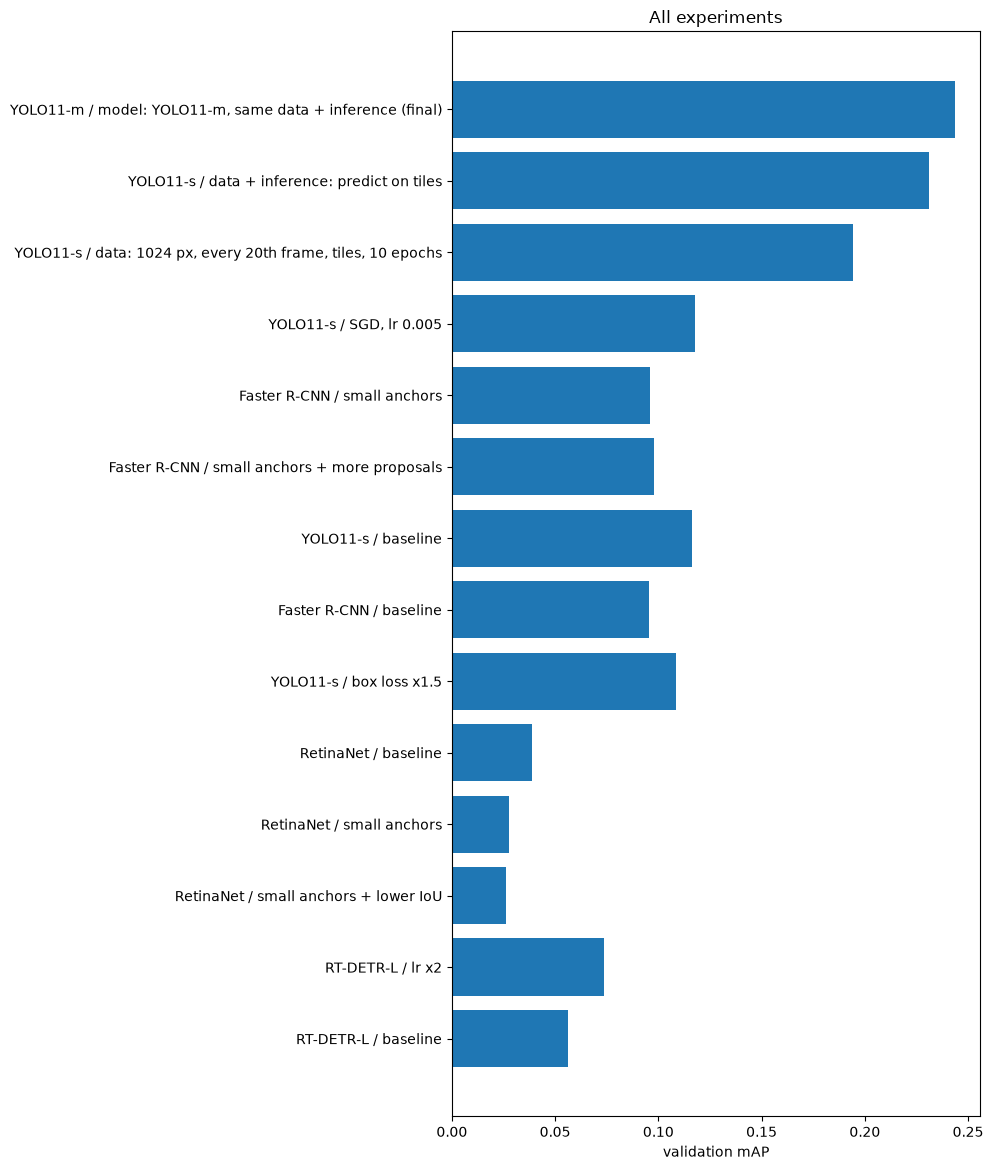

,notebook,run,mAP,AP50,AP_small,AP_medium,AP_large,ms/img,train_min
26,07,"YOLO11-m / model: YOLO11-m, same data + infere...",0.2436,0.4714,0.1524,0.2128,0.4325,349.4,313.2
25,07,YOLO11-s / data + inference: predict on tiles,0.2312,0.4415,0.1894,0.2129,0.3910,316.3,0.0
24,07,"YOLO11-s / data: 1024 px, every 20th frame, ti...",0.1943,0.3731,0.1171,0.1736,0.3622,118.9,154.9
8,05,"YOLO11-s / SGD, lr 0.005",0.1177,0.2303,0.0305,0.0855,0.2661,150.0,1.2
6,05,YOLO11-s / baseline,0.1164,0.2226,0.0344,0.0757,0.2729,155.9,2.6
19,05,"YOLO11-s / SGD, lr 0.005",0.1159,0.2182,0.0252,0.0999,0.2605,123.6,1.0
7,05,YOLO11-s / box loss x1.5,0.1084,0.2105,0.0353,0.0740,0.2538,145.2,1.3
2,03,Faster R-CNN / small anchors + more proposals,0.0977,0.2282,0.0388,0.0867,0.2325,321.2,3.0
1,03,Faster R-CNN / small anchors,0.0961,0.2190,0.0416,0.0839,0.2243,268.0,3.0
11,03,Faster R-CNN / baseline,0.0953,0.2232,0.0417,0.0754,0.2266,212.8,2.8


In [25]:
table = pd.read_csv(RESULTS_FILE, dtype={"notebook": str})
table["run"] = table["model"] + " / " + table["experiment"]
table = table.sort_values("mAP")

fig, ax = plt.subplots(figsize=(10, 0.4 * len(table) + 1))
ax.barh(table["run"], table["mAP"])
ax.set_xlabel("validation mAP")
ax.set_title("All experiments")
plt.tight_layout()
plt.savefig(f"{IMAGES}/07_summary.png", dpi=110)
plt.show()

table[["notebook", "run", "mAP", "AP50", "AP_small", "AP_medium", "AP_large", "ms/img", "train_min"]].iloc[::-1]

## Figures for the report
A clean summary: only the last run of every experiment, without the broken RT-DETR runs (before the warm-up fix).
And the best run of every model by object size.

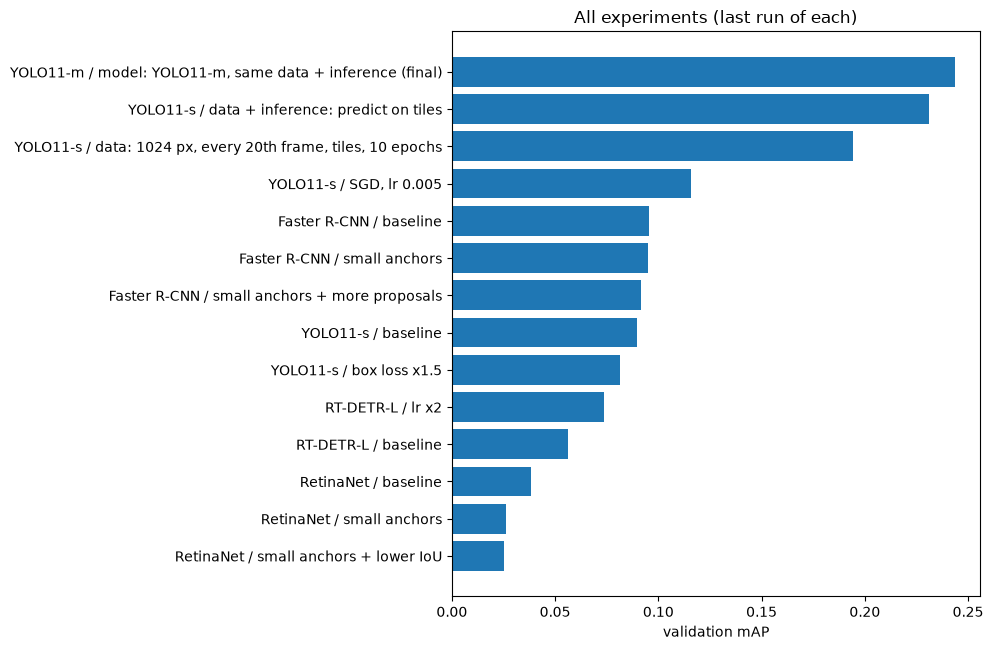

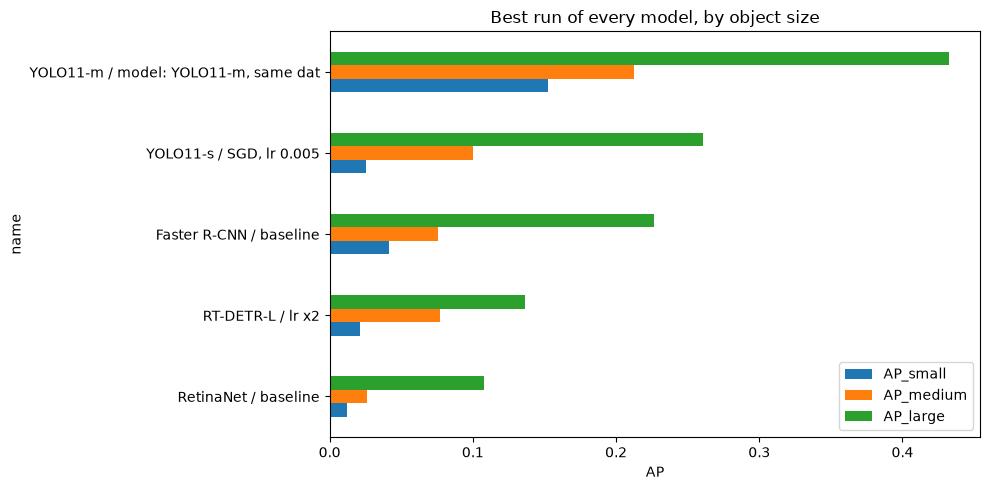

In [27]:
table = pd.read_csv(RESULTS_FILE, dtype={"notebook": str})
# Keep only the last run of every experiment.
table = table.drop_duplicates(subset=["model", "experiment"], keep="last")
# Remove the RT-DETR runs before the warm-up fix (mAP = 0).
table = table[table["mAP"] > 0.001]
table["run"] = table["model"] + " / " + table["experiment"]
table = table.sort_values("mAP")

fig, ax = plt.subplots(figsize=(10, 0.4 * len(table) + 1))
ax.barh(table["run"], table["mAP"])
ax.set_xlabel("validation mAP")
ax.set_title("All experiments (last run of each)")
plt.tight_layout()
plt.savefig(f"{IMAGES}/07_summary_clean.png", dpi=110)
plt.show()

# Best run of every model with the short budget (notebooks 03-06) and the final model.
short = table[table["notebook"].isin(["03", "04", "05", "06"])]
best = short.drop_duplicates(subset="model", keep="last")
final = table[(table["notebook"] == "07") & (table["model"] == "YOLO11-m")]
sizes = pd.concat([best, final])
sizes["name"] = sizes["model"] + " / " + sizes["experiment"].str[:25]
sizes = sizes.set_index("name")[["AP_small", "AP_medium", "AP_large"]]

sizes.plot.barh(figsize=(10, 5))
plt.xlabel("AP")
plt.title("Best run of every model, by object size")
plt.tight_layout()
plt.savefig(f"{IMAGES}/07_by_size.png", dpi=110)
plt.show()

## Conclusions

| step | model | what changes | mAP | AP50 | AP_small | AP_medium | AP_large | ms/img | train_min |
|---|---|---|---|---|---|---|---|---|---|
| 1 | YOLO11-s | baseline: 640 px, every 100th frame, 3 epochs | 0.0896 | 0.1820 | 0.0277 | 0.0796 | 0.2216 | 171.6 | 2.0 |
| 2 | YOLO11-s | **data**: 1024 px, every 20th frame, tiles, 10 epochs | 0.1943 | 0.3731 | 0.1171 | 0.1736 | 0.3622 | 118.9 | 154.9 |
| 3 | YOLO11-s | **inference**: + predict on tiles | 0.2312 | 0.4415 | **0.1894** | 0.2129 | 0.3910 | 316.3 | 0 |
| 4 | YOLO11-m | **model**: bigger model, same data + inference | **0.2436** | **0.4714** | 0.1524 | 0.2128 | **0.4325** | 349.4 | 313.2 |

* **Final model:** YOLO11-m, 1024 px, every 20th frame, training on tiles, prediction on tiles, 10 epochs, SGD / Ultralytics defaults, seed fixed.
* **Validation mAP:** 0.2436. **Kaggle public score:** 0.31.
* We also tried 15 epochs: the Kaggle score was lower, so we keep 10 epochs.

**Which change helped most**
* **Data (step 2): +0.105 mAP**, more than 2 times better. AP_small is 4 times better (0.028 → 0.117). Small objects are the main problem of this dataset, and the bigger input + tiles make them bigger for the model. Note: this step also has more frames and more epochs, so it is "more data and more training".
* **Inference (step 3): +0.037 mAP** with no new training. AP_small grows again (0.117 → 0.189). But prediction is 2.7 times slower (119 → 316 ms per image), because the model looks at 5 images per frame.
* **Model (step 4): +0.012 mAP**, the smallest effect. YOLO11-m is better on large objects (0.391 → 0.433) and on AP50, but worse on small objects (0.189 → 0.152). Training takes 2 times longer (155 → 313 min).
* So for this dataset **the data and the inference matter more than the model size**.

**Comparison with notebooks 03-06** (same short budget: 640 px, 3 epochs)
* YOLO11-s (0.09-0.12) > Faster R-CNN (0.09-0.10) > RT-DETR-L (0.06-0.07) > RetinaNet (0.03-0.04).
* YOLO was the best and the fastest model family, so we built the final pipeline on it.